<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/jobsheet%20dataset%20AntiBurnOut/JS11/09_Classification_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS11: Support Vector Machine (SVM) Classification - Dataset AntiBurnOut

**Identitas Mahasiswa:**
- **Nama**  : MUHAMMAD ANKA REZA
- **NIM**   : 254107023002
- **Kelas** : TI/3H

---

### Deskripsi Praktikum:
Praktikum ini menerapkan algoritma **Support Vector Machine (SVM)** untuk klasifikasi risiko burnout pekerja. Diuji performa pemisahan hyperplane menggunakan **Kernel Linear** dan **Kernel Radial Basis Function (RBF)**, serta analisis vektor pendukung (*support vectors*).

### Langkah 1: Memuat Data dan Penyiapan Fitur

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

dataset_candidates = [
    'mental_health_burnout_prediction_dataset.csv',
    '../mental_health_burnout_prediction_dataset.csv',
    'jobsheet dataset AntiBurnOut/mental_health_burnout_prediction_dataset.csv'
]
dataset_path = next((p for p in dataset_candidates if os.path.exists(p)), 'mental_health_burnout_prediction_dataset.csv')
df = pd.read_csv(dataset_path)

features = ['Work_Hours_Per_Week', 'Sleep_Hours', 'Anxiety_Score', 
            'Depression_Score', 'Mood_Score', 'Emotional_Stability']

X = df[features].copy()
for col in features:
    X[col] = X[col].fillna(X[col].median())

y = df['Burnout_Risk']

# Subsampling 6.000 data untuk menjaga waktu komputasi kuadratik SVM (O(n^2))
np.random.seed(42)
sample_idx = np.random.choice(len(X), 6000, replace=False)
X_sub = X.iloc[sample_idx]
y_sub = y.iloc[sample_idx]

X_train, X_test, y_train, y_test = train_test_split(X_sub, y_sub, test_size=0.25, random_state=42, stratify=y_sub)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Data Latih SVM: {X_train_scaled.shape}, Data Uji: {X_test_scaled.shape}")

Data Latih SVM: (4500, 6), Data Uji: (1500, 6)


### Langkah 2: Eksperimen Kernel SVM (Linear vs RBF)

In [2]:
# 1. SVM Kernel Linear
svm_linear = SVC(kernel='linear', C=1.0, random_state=42)
svm_linear.fit(X_train_scaled, y_train)
y_pred_linear = svm_linear.predict(X_test_scaled)
acc_linear = accuracy_score(y_test, y_pred_linear)

# 2. SVM Kernel RBF
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_rbf.fit(X_train_scaled, y_train)
y_pred_rbf = svm_rbf.predict(X_test_scaled)
acc_rbf = accuracy_score(y_test, y_pred_rbf)

print(f"Akurasi SVM Kernel Linear : {acc_linear * 100:.2f}%")
print(f"Akurasi SVM Kernel RBF    : {acc_rbf * 100:.2f}%")
print(f"Jumlah Support Vectors RBF: {len(svm_rbf.support_)}")

Akurasi SVM Kernel Linear : 80.87%
Akurasi SVM Kernel RBF    : 81.67%
Jumlah Support Vectors RBF: 1925


### Langkah 3: Evaluasi Detail dan Confusion Matrix (SVM RBF)

=== Classification Report (SVM RBF Kernel) ===
              precision    recall  f1-score   support

        High       0.85      0.79      0.82       300
         Low       0.90      0.87      0.89       754
    Moderate       0.68      0.74      0.70       446

    accuracy                           0.82      1500
   macro avg       0.81      0.80      0.80      1500
weighted avg       0.82      0.82      0.82      1500



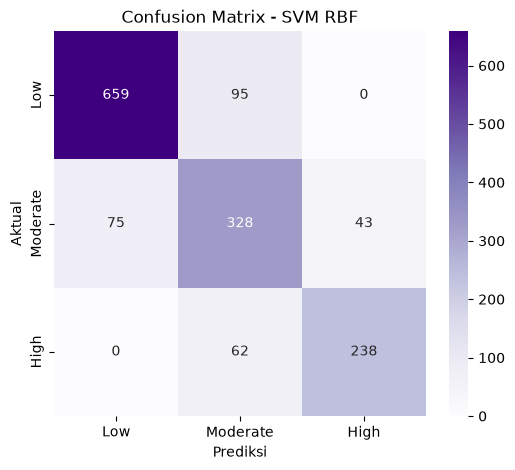

In [3]:
print("=== Classification Report (SVM RBF Kernel) ===")
print(classification_report(y_test, y_pred_rbf))

labels_order = ['Low', 'Moderate', 'High']
cm = confusion_matrix(y_test, y_pred_rbf, labels=labels_order)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=labels_order, yticklabels=labels_order)
plt.title('Confusion Matrix - SVM RBF', fontsize=12)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

### Kesimpulan JS11:
1. Kernel RBF menunjukkan fleksibilitas pemisahan hyperplane non-linear yang lebih baik pada indikator kesehatan mental dibandingkan kernel linear sederhana.
2. Penggunaan standarisasi fitur (`StandardScaler`) menjadi kunci penting stabilitas konvergensi algoritma SVM.